# Diabetes Prediction Using Neural Networks
This notebook demonstrates an end-to-end machine learning pipeline predicting diabetes using TensorFlow/Keras and the Pima Indians Diabetes Dataset (`diabetes.csv`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Load dataset directly from diabetes.csv
df = pd.read_csv("diabetes.csv")
print("Original dataset shape:", df.shape)
df.head()

Original dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


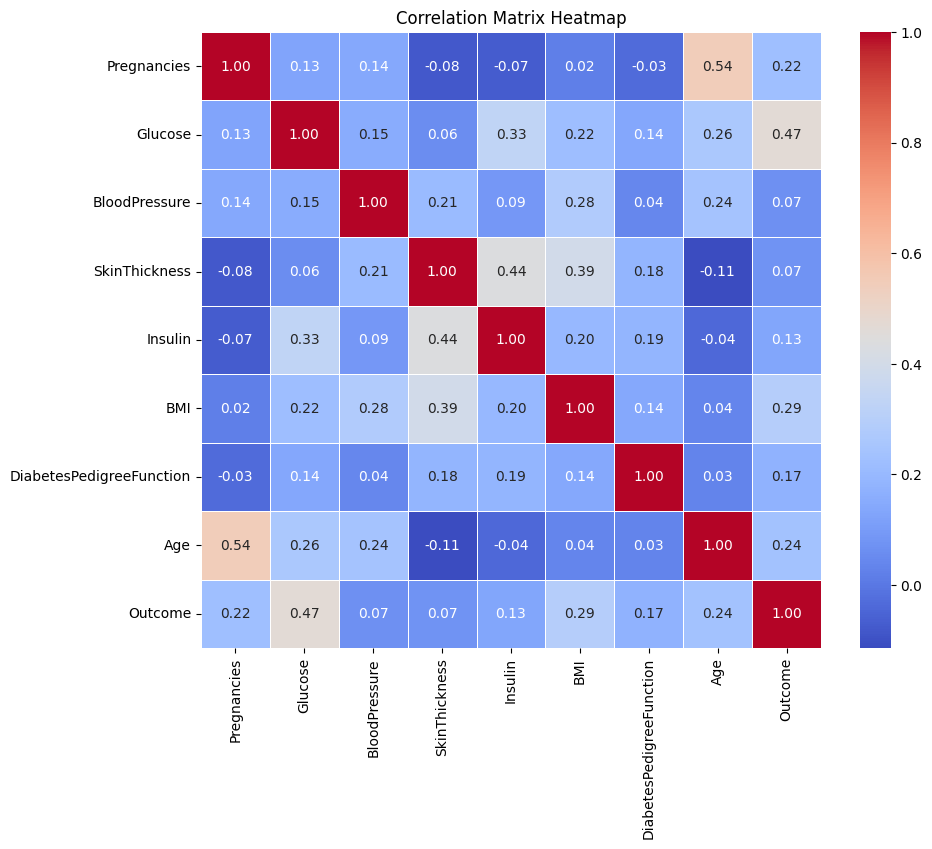

In [2]:
# 2. Exploratory Data Analysis: Correlation Matrix Heatmap
correlation_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [3]:
# 3. Data Cleaning & Class Balancing
zero_features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Count zeros in each row
df["zero_count"] = (df[zero_features] == 0).sum(axis=1)

# Separate classes
df_0 = df[df["Outcome"] == 0]  # Majority class
df_1 = df[df["Outcome"] == 1]  # Minority class

# Sort by zero count and drop rows with the most missing/zero values
df_0 = df_0.sort_values(by="zero_count", ascending=False).iloc[232:]

# Drop temporary zero_count column
df_0 = df_0.drop(columns=["zero_count"])
df_1 = df_1.drop(columns=["zero_count"])

# Combine and shuffle to create a balanced dataset in-memory
df = pd.concat([df_0, df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset balanced! New class distribution:")
print(df["Outcome"].value_counts())

Dataset balanced! New class distribution:
Outcome
0    268
1    268
Name: count, dtype: int64


In [4]:
# 4. Impute remaining zeros with column medians
for col in zero_features:
    median_value = df[col].median()
    df[col] = df[col].replace(0, median_value)

print("Remaining zero counts:")
print((df[zero_features] == 0).sum())

Remaining zero counts:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [5]:
# 5. Feature Scaling using MinMaxScaler
scaler = MinMaxScaler()
df[df.columns[:-1]] = scaler.fit_transform(df[df.columns[:-1]])
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0.117647,0.174825,0.533333,0.086957,0.074519,0.243354,0.197859,0.066667,0
1,0.117647,0.363636,0.311111,0.206522,0.058894,0.292434,0.099786,0.016667,0
2,0.235294,0.195804,0.733333,0.173913,0.050481,0.435583,0.031692,0.066667,0
3,0.235294,0.377622,0.577778,0.141304,0.103365,0.208589,0.014133,0.100000,0
4,0.000000,0.475524,0.355556,0.065217,0.109375,0.073620,0.157173,0.000000,0


In [6]:
# 6. Train/Test Split with Stratification
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Training set shape: (428, 8), Test set shape: (108, 8)


In [7]:
# 7. Build Neural Network Architecture
model = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

C:\Users\amjad\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 8. Train the Model
history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), verbose=1)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.5061 - loss: 0.7076 - val_accuracy: 0.5833 - val_loss: 0.6909
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5962 - loss: 0.6815 - val_accuracy: 0.5185 - val_loss: 0.6788
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6167 - loss: 0.6730 - val_accuracy: 0.5648 - val_loss: 0.6700
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5881 - loss: 0.6686 - val_accuracy: 0.6204 - val_loss: 0.6624
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6506 - loss: 0.6575 - val_accuracy: 0.6389 - val_loss: 0.6553
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6708 - loss: 0.6404 - val_accuracy: 0.6481 - val_loss: 0.6477
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6866 - loss: 0.6387 - val_accuracy: 0.6667 - val_loss: 0.6405
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7005 - loss: 0.6327 - val_accuracy: 0.6667 - v

In [9]:
# 9. Model Evaluation & Performance Metrics
y_pred = (model.predict(X_test) > 0.5).astype("int32")

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Accuracy: 0.8148
Precision: 0.7656
Recall: 0.9074
F1-Score: 0.8305

Confusion Matrix:
[[39 15]
 [ 5 49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.72      0.80        54
           1       0.77      0.91      0.83        54

    accuracy                           0.81       108
   macro avg       0.83      0.81      0.81       108
weighted avg       0.83      0.81      0.81       108

